# 顺序结构

In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

class OverAllState(TypedDict):
    username: str
    greeting: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "greeting": "Dear " + state["username"]
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "output": state["greeting"] + "，你好！"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_edge(START, "node_a")
builder.add_sequence([node_a, node_b])

graph = builder.compile()
res = graph.invoke({"username": "小黄"})
print(res)

{'username': '小黄', 'greeting': 'Dear 小黄', 'output': 'Dear 小黄，你好！'}


# 分支结构

## 静态分支

### 并行分支

In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"topic": "猫咪"})
print(res)

{'topic': '猫咪', 'poem': '《题猫》\n轻身扑蝶过墙东，爪印梅花雪地中。\n昼伏夜行如有约，一声清啸鼠仓空。\n\n注：我的创作思路是抓住猫咪轻盈敏捷、爪印如梅的形态特征，以及昼伏夜出的生活习性。通过“扑蝶过墙”的动态描写展现其灵动，用“爪印梅花”的意象暗喻雪泥鸿爪的古典意境。后两句以拟人手法写其与人类的默契，尾句“清啸鼠仓空”既显猫威，又暗含除害利民之意，使小诗在童趣之外更添几分深意。', 'joke': '一只猫在街上遇到一只老鼠，老鼠挑衅地说：“你天天吃猫粮，凭什么抓我？”\n\n猫慢悠悠地掏出手机，打开外卖APP：“你看，我点了‘鼠’于我的外卖，就差你签收了。”'}


### 条件分支

In [4]:
from collections.abc import Sequence
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    ci_poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content
    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的词")]).content
    return {
        "ci_poem": ci_poem
    }

def router(state: OverAllState) -> Sequence[Literal["a", "b", "c"]]:
    if "诗" in state["content_type"]:
        return ["a", "c"]
    return ["b", "c"]

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(
    START,
    router,
    path_map={
        "a": "node_a",
        "b": "node_b",
        "c": "node_c",
    }
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
print(joke_res)

============================== -> poem_res <- ==============================
{'topic': '布偶狗', 'content_type': '诗', 'poem': '《布偶狗》\n绒耳垂垂锦作裘，憨姿常伴小窗幽。\n不吠惊回千里梦，静卧芳茵春复秋。\n\n注：我的创作思路是抓住布偶狗静默陪伴的特点，通过“绒耳锦裘”的细腻刻画展现其可爱外形。后两句以对比手法突出其“不吠”的温顺性格，尾句“静卧芳茵”既呼应布偶的静态美，又暗喻时光流转中恒久的陪伴，使玩具狗的形象兼具物性之美与情感温度。', 'ci_poem': '《鹧鸪天·布偶狗》\n绒耳垂垂软系铃，玻璃眼底澈如冰。\n偎人常伴绣花榻，衔月时追剪纸翎。\n穿锦幔，扑流萤，一团憨态任斜横。\n顽皮也效狸奴样，滚入罗裙呓语轻。\n\n注：我的创作思路是围绕布偶狗“毛绒玩具”的物理特性与拟人化情趣展开。通过“绒耳系铃”“玻璃眼”等意象突出其材质特征，以“偎人”“衔月”“扑萤”等动态描写赋予其灵性。下阕“效狸奴样”的顽皮与“呓语轻”的憨态，既保持玩具的静止感，又暗含主客互动的温情，体现布偶狗作为陪伴物的独特意趣。'}
============================== -> joke_res <- ==============================
{'topic': '布偶狗', 'content_type': '笑话', 'ci_poem': '《临江仙·布偶狗》\n绒团乖巧憨态掬，眸清尾短身柔。\n偎人怀里作娇羞。\n伴读寒窗下，同卧小床头。\n\n常恨此身无血肉，难随君步云游。\n也思衔月送归舟。\n衷情虽未语，挚爱在心头。\n\n注：我的仿写创作思路是捕捉布偶狗作为玩偶的静态特征与动态情感。通过“绒团”“眸清尾短”等意象刻画其可爱形态，再以“偎人”“伴读”等动作赋予其生命感。下阕转折于玩偶无血肉的遗憾，却以“衔月送归舟”的想象升华情感，最终在“衷情未语”中完成对无声挚爱的诗意表达。', 'joke': '## 布偶狗\n> 我买了一只布偶狗，卖家说它特别乖，不掉毛、不拆家、不用遛。  \n> 我信了。  \n> 结果拿回家第一天，它确实一动不动。  \n> 我摸摸它的头：“真乖。”  \n> 第二天，它还是一动不动。

2026-10-23 18:37:27.987 | INFO     | __main__:audit_node:40 - 任务节点全部执行完毕，诗 已生成，笑话 已生成


{'topic': '布偶狗', 'poem': '《布偶狗》\n绒身棉耳软茸茸，半假半真憨态浓。\n不吠深宵惊客梦，常偎膝上暖寒冬。\n\n注：我的创作思路是抓住布偶狗“似真非真”的玩具属性，通过“绒身棉耳”的质感描写与“不吠”“常偎”的行为对比，展现其作为玩偶的静默陪伴特质。末句“暖寒冬”既呼应布偶的保暖功能，又暗含情感慰藉，使无机之物生出温度。', 'joke': '## 布偶狗\n\n我买了一只布偶狗，店家说它特别乖，不用喂食不用遛，唯一需要的就是每天跟它说说话。\n\n第一天我回家，对着它说：“今天工作好累啊。”布偶狗一动不动，但我觉得它的眼神好像在说“辛苦啦”。\n\n第二天我说：“老板今天又骂我了。”布偶狗还是不动，但嘴角好像微微上扬了一点。\n\n第三天我说：“我感觉自己好没用。”布偶狗突然开口了：“你说得对。”\n\n我吓得跳起来：“你会说话？！”\n\n布偶狗点点头：“嗯，我是高级AI布偶，专门提供情绪价值。所以刚才那句是付费内容，麻烦结一下。”\n\n我：“多少钱？”\n\n布偶狗：“一百。”\n\n我：“就一句话一百？！”\n\n布偶狗：“对啊，心理咨询不都这个价嘛。对了，你昨天骂老板那两句，我打折收你八十就行。”\n\n我掏出一百块塞进它嘴里：“那我问你，你作为一个布偶狗，最大的优点是什么？”\n\n布偶狗把钱咽下去，认真地说：“我永远不会背叛你，因为我连门都出不去。”\n\n……我竟无法反驳。'}


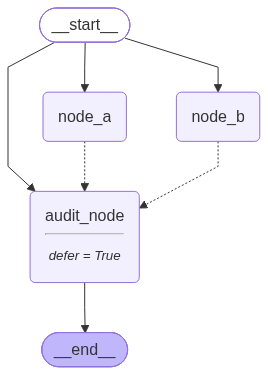

In [6]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from loguru import logger

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content

    return {
        "joke": joke
    }

def audit_node(state: OverAllState) -> OverAllState:
    logger.info(f"任务节点全部执行完毕，诗 {'已生成' if state['poem'] else '未生成'}，笑话 {'已生成' if state['joke'] else '未生成'}")

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("audit_node", audit_node, defer=True)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge(START, "audit_node")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("audit_node", END)

graph = builder.compile()
res = graph.invoke({"topic": "布偶狗"})
print(res)

from IPython.display import display

display(graph)

## 动态分支

### 并行节点

{'poem': '## 《布偶狗》\n\n总以为尾巴能测度爱的深浅，\n直到毛绒磨出棉絮的弧线。\n你鼻尖的纽扣，映着夕照，\n比真实的湿润更懂得缠绕。\n\n白日里你是静默的布偶，\n暗处却用纤维编制绳索。\n当月光爬上腈纶的脊背，\n棉絮的河道便涨满潮水。\n\n他们笑你分不清晨昏的界线，\n可谁知道棉布裹着雷暴的闪电？\n我渐渐变成你怀里的填充物，\n在针脚间听着线头的低诉。', 'ci_poem': '《临江仙·布偶狗》\n绒线织成憨态，棉云叠作温柔。\n琉璃珠子点双眸。\n尾摇斜照里，耳竖小窗头。\n\n长伴绣衾竹榻，时偎书案茶瓯。\n殷勤迎客复何求？\n心虽无血肉，情亦解烦忧。\n\n注：我的创作思路是抓住布偶狗作为毛绒玩具的核心特征，通过“绒线”“棉云”等意象表现其材质，以“琉璃珠子”比喻眼睛的晶亮。下阕通过“绣衾竹榻”“书案茶瓯”等生活场景展现其陪伴功能，尾句“心虽无血肉，情亦解烦忧”既点明其无生命特质，又赋予其情感价值，形成诗意张力。', 'joke': '## 布偶狗\n\n小明养了一只布偶猫，特别喜欢。有天他跟朋友炫耀：“我家猫特别乖，像布偶一样，抱起来软乎乎的，随便撸都不生气。”\n\n朋友说：“那有什么，我家狗才是真布偶。”\n\n小明不信，跑去朋友家看。果然，那只狗躺在地上一动不动，任人摆布，翻过来倒过去都没反应。\n\n小明惊叹：“怎么训练的？”\n\n朋友淡定地说：“没训练，这是我从布偶猫那儿学来的——它以为自己在装死，其实真睡着了。”'}


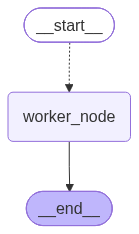

In [7]:
from typing import TypedDict, Literal
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

CONTENT_TYPES = ["poem", "ci_poem", "joke"]

model = ChatDeepSeek(
    model = "deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    ci_poem: str
    joke: str

class WorkerState(TypedDict):
    """
    私有状态，只对 Worker 节点可用
    """
    content_type: Literal["poem", "ci_poem", "joke"]
    prompt: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    poem: str
    ci_poem: str
    joke: str

def worker_node(state: WorkerState) -> OutputState:
    content_type = state["content_type"]
    prompt = state["prompt"]

    content = model.invoke([HumanMessage(prompt)]).content
    return {
        content_type: content
    }

def router(state: InputState) -> Sequence[Send]:
    prompt = "请生成关于 {} 的 {}"
    english2chinese = {
        "poem": "一首诗",
        "ci_poem": "一首词",
        "joke": "一个笑话"
    }

    topic = state["topic"]

    return [Send(
            "worker_node",
            {
                "content_type": content_type,
                "prompt": prompt.format(topic, english2chinese[content_type]),
            }
        ) for content_type in CONTENT_TYPES
    ]

builder = StateGraph(state_schema=OverAllState, input_schema=InputState, output_schema=OutputState)
builder.add_node("worker_node", worker_node)
builder.add_conditional_edges(
    START,
    router,
    path_map=["worker_node"]
)
builder.add_edge("worker_node", END)

graph = builder.compile()
res = graph.invoke({"topic": "布偶狗"})
print(res)

from IPython.display import display
display(graph)

### 条件分支

============================== -> poem <- ==============================
{'topic': '布偶猫', 'content_type': 'poem', 'poem': '《布偶猫》\n蓝瞳如海雪绒身，静卧瑶台不染尘。\n轻吻指尖娇语软，仙姿何必问前因。\n\n注：我的创作思路是抓住布偶猫的蓝眼、雪白长毛、温顺亲人的特点。首句以“蓝瞳如海”喻其清澈眼眸，“雪绒身”状其蓬松白毛。次句“瑶台”仙化其高雅姿态。第三句“轻吻指尖”表现其亲昵个性，结句“仙姿何必问前因”暗合布偶猫“仙女猫”的别称，赋予其神秘仙气。全诗通过意象组合展现布偶猫的灵秀可人。'}
============================== -> joke <- ==============================
{'topic': '布偶猫', 'content_type': 'joke', 'joke': '一只布偶猫走进酒吧，对吧唧吧唧喝了一杯牛奶。\n\n酒保问：“要不要再来一杯？”\n\n布偶猫说：“不了，我布偶猫，喝一杯就‘软’了。”'}
============================== -> illegal <- ==============================
{'topic': '布偶猫', 'content_type': 'illegal', 'poem': '无', 'joke': '无'}


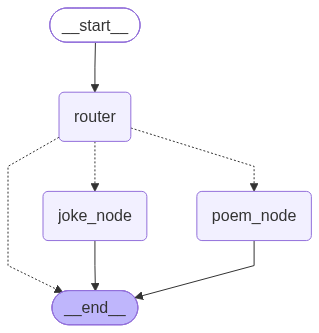

In [9]:
from typing import TypedDict, Literal
from langgraph.types import Command
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: Literal["poem", "joke"]
    poem: str
    joke: str

def router(state: OverAllState) -> Command:
    content_type = state["content_type"]

    if content_type == "poem":
        return Command (
            goto="poem_node"
        )
    elif content_type == "joke":
        return Command (
            goto="joke_node"
        )
    return Command (
        update={'poem': '无', 'joke': '无'},
        goto=END
    )

def poem_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一首关于 {topic} 的七言绝句"
    poem = model.invoke([HumanMessage(prompt)]).content
    return {
        "poem": poem
    }

def joke_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一个关于 {topic} 的冷笑话"
    joke = model.invoke([HumanMessage(prompt)]).content
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("router", router)
builder.add_node("poem_node", poem_node)
builder.add_node("joke_node", joke_node)
builder.add_edge(START, "router")
builder.add_edge("poem_node", END)
builder.add_edge("joke_node", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶猫", "content_type": "poem"})
joke_res = graph.invoke({"topic": "布偶猫", "content_type": "joke"})

# 这里故意传入一个不符合 Literal["poem", "joke"] 的值，
# 用来观察运行时兜底分支。
# 注意：Literal 主要服务于静态类型检查，
# 默认不会在 Python 运行时阻止非法值传入。
illegal_res = graph.invoke({
    "topic": "布偶猫",
    "content_type": "illegal"
})

print('=' * 30, '-> poem <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke <-', '=' * 30)
print(joke_res)
print('=' * 30, '-> illegal <-', '=' * 30)
print(illegal_res)

from IPython.display import display
display(graph)

# 多分支汇聚Fan-in

## 静态扇入

或触发

2026-10-23 19:44:06.664 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-10-23 19:44:06.666 | INFO     | __main__:node_b:17 - cur_step: 2, node_b 被触发
2026-10-23 19:44:06.667 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-10-23 19:44:06.668 | INFO     | __main__:node_e:32 - cur_step: 3, node_e 被触发
2026-10-23 19:44:06.668 | INFO     | __main__:node_d:27 - cur_step: 3, node_d 被触发
2026-10-23 19:44:06.669 | INFO     | __main__:node_e:32 - cur_step: 4, node_e 被触发


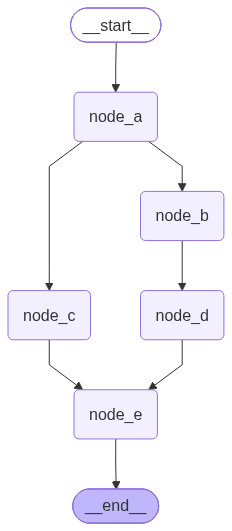

In [12]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}

def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}

def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")

# 独立触发：node_c 完成后可以触发 node_e
builder.add_edge("node_c", "node_e")
# 独立触发：node_d 完成后可以触发 node_e
builder.add_edge("node_d", "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)

与触发

2026-10-23 19:39:37.016 | INFO     | __main__:node_a:11 - cur_step: 1, node_a 被触发
2026-10-23 19:39:37.017 | INFO     | __main__:node_b:16 - cur_step: 2, node_b 被触发
2026-10-23 19:39:37.018 | INFO     | __main__:node_c:21 - cur_step: 2, node_c 被触发
2026-10-23 19:39:37.020 | INFO     | __main__:node_d:26 - cur_step: 3, node_d 被触发
2026-10-23 19:39:37.020 | INFO     | __main__:node_e:31 - cur_step: 4, node_e 被触发


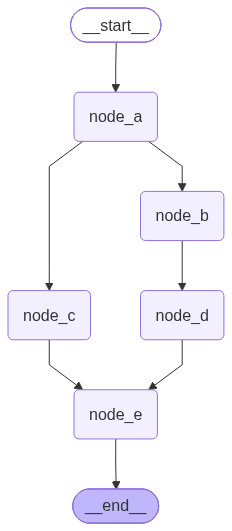

In [11]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig
from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}

def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}

def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")
builder.add_edge(["node_c", "node_d"], "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)


## 动态扇入

2026-10-23 20:01:44.643 | INFO     | __main__:reducer_node:40 - reducer entries: [('hello', 1), ('world', 1), ('hello', 1), ('Atguigu', 1), ('hello', 1), ('LLM', 1)]
2026-10-23 20:01:44.643 | INFO     | __main__:reducer_node:49 - reducer shuffle entries: {'hello': [1, 1, 1], 'world': [1], 'Atguigu': [1], 'LLM': [1]}


{'input_values': ['hello world', 'hello Atguigu', 'hello LLM'], 'entries': [('hello', 1), ('world', 1), ('hello', 1), ('Atguigu', 1), ('hello', 1), ('LLM', 1)], 'word_counts': {'hello': 3, 'world': 1, 'Atguigu': 1, 'LLM': 1}}


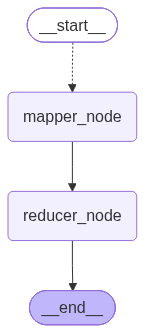

In [13]:
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from _collections_abc import Sequence
from operator import add
from loguru import logger

class OverAllState(TypedDict):
    input_values: list[str]
    entries: Annotated[list[tuple[str, int]], add]
    word_counts: dict[str, int]

def router_map(state: OverAllState) -> Sequence[Send]:
    input_values = state["input_values"]
    tasks = []
    for input_value in input_values:
        tasks.append(
            Send(
                "mapper_node",
                {"input_value": input_value}
            )
        )
    return tasks

class MaperInputState(TypedDict):
    input_value: str

def mapper_node(state: MaperInputState) -> OverAllState:
    input_value = state["input_value"]
    words = input_value.split(" ")
    entries = []
    for word in words:
        entries.append((word, 1))
    return {
        "entries": entries
    }

def reducer_node(state: OverAllState) -> OverAllState:
    entries = state["entries"]
    logger.info("reducer entries: {}", entries)

    shuffle_dict = {}
    for k, v in entries:
        if k not in shuffle_dict:
            shuffle_dict[k] = [v]
        else:
            shuffle_dict[k].append(v)

    logger.info("reducer shuffle entries: {}", shuffle_dict)

    reduce_dict = {}
    for k, v in shuffle_dict.items():
        reduce_dict[k] = sum(v)

    return {
        "word_counts": reduce_dict
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("mapper_node", mapper_node)
builder.add_node("reducer_node", reducer_node)
builder.add_conditional_edges(START, router_map, path_map=["mapper_node"])
builder.add_edge("mapper_node", "reducer_node")
builder.add_edge("reducer_node", END)

graph = builder.compile()
word_counts = graph.invoke(
    {"input_values": [
        "hello world",
        "hello Atguigu",
        "hello LLM"
    ]}
)

print(word_counts)

from IPython.display import display
display(graph)

# 循环结构

静态实现

============================== -> ai_res <- ==============================
user_input:  帮我查询杭州当日天气和AI热点
final_answer:  查询完成，以下是结果：

## 🌤️ 杭州当日天气
- **天气**：晴朗
- **风力**：东南风三级
- **气温**：25~30 ℃

天气晴好，气温舒适，注意防晒～

## 🤖 AI 热点
- **Anthropic 发布 Claude Opus-4.8**：有用户发现，通过 API 用中文向其发送"你是谁？"时，大多数情况下它返回的却是"Qwen"或"Deepseek"，这一现象引发了关注与讨论。

（说明：AI 热点查询前几次遇到网络波动，重试后已成功获取。）
================================ System Message ================================

如果工具调用失败，必须重新调用直至成功
================================ Human Message =================================

帮我查询杭州当日天气和AI热点
================================== Ai Message ==================================

我来帮您查询杭州的天气和AI热点。
Tool Calls:
  get_weather (call_00_zY34c2nEMAFBikeOw8ix8613)
 Call ID: call_00_zY34c2nEMAFBikeOw8ix8613
  Args:
    city: 杭州
  get_news (call_01_KAhZ1Yyz3Wy9KRxg1r889436)
 Call ID: call_01_KAhZ1Yyz3Wy9KRxg1r889436
  Args:
    domain: AI
================================= Tool Message =================================
Name: get_weather

杭州 今天

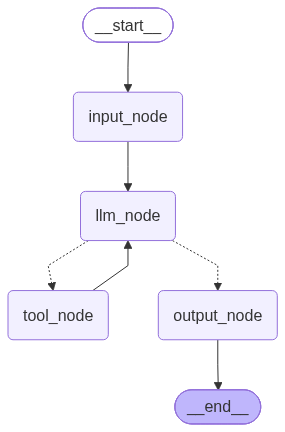

In [14]:
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek
from random import randint

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str="北京"):
    """
    查询指定城市当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气晴朗，东南风三级，气温 25~30 ℃"

@tool(parse_docstring=True)
def get_news(domain: Literal["AI", "食品安全"]):
    """
    查询特定领域的当日热点

    Args:
        domain: 特定领域
    """
    if domain == "AI":
        return "Anthropic 发布了 Claude Opus-4.8，但通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。"
    else:
        return "双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍"

tools = [get_weather, get_news]

model_with_tools = model.bind_tools(tools=tools)

class OverAllState(MessagesState):
    user_input: str
    final_answer: str

def input_node(state: OverAllState) ->OverAllState:
    return {
        "messages": [HumanMessage(state["user_input"])],
    }

def llm_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = model_with_tools.invoke(messages)
    return {
        "messages": [ai_msg],
    }

def tool_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = messages[-1]
    tool_calls = ai_msg.tool_calls

    fail_prob = 6 # 失败概率，6表示 60% 概率失败，7 -> 70%，8 -> 80%，依次类推

    for tool_call in tool_calls:
        if tool_call["name"] == "get_weather":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_weather.invoke(tool_call))
        elif tool_call["name"] == "get_news":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_news.invoke(tool_call))
        else:
            messages.append(
                ToolMessage(
                    content="工具名称错误，调用失败，请重试",
                    tool_call_id=tool_call["id"]
                )
            )

    return {
        "messages": messages
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "final_answer": state["messages"][-1].content
    }

def router(state: OverAllState) -> Literal["tool_node", "output_node"]:
    messages = state["messages"]
    lst_msg = messages[-1]

    if lst_msg.tool_calls:
        return "tool_node"
    return "output_node"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("input_node", input_node)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "input_node")
builder.add_edge("input_node", "llm_node")
builder.add_conditional_edges(
    "llm_node",
    router
)
builder.add_edge("tool_node", "llm_node")
builder.add_edge("output_node", END)

graph = builder.compile()
ai_res = graph.invoke({
    "user_input": "帮我查询杭州当日天气和AI热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})
food_safety_res = graph.invoke({
    "user_input": "帮我查询当日天气和食品安全相关的热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})

print('=' * 30, '-> ai_res <-', '=' * 30)
print("user_input: ", ai_res["user_input"])
print("final_answer: ", ai_res["final_answer"])
for msg in ai_res["messages"]:
    msg.pretty_print()

print('=' * 30, '-> food_safety_res <-', '=' * 30)
print("user_input: ", food_safety_res["user_input"])
print("final_answer: ", food_safety_res["final_answer"])
for msg in food_safety_res["messages"]:
    msg.pretty_print()

from IPython.display import display
display(graph)

动态实现

In [ ]:
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langgraph.types import Command
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from random import randint
from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str="北京"):
    """
    查询指定城市当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气晴朗，东南风三级，气温 25~30 ℃"

@tool(parse_docstring=True)
def get_news(domain: Literal["AI", "食品安全"]):
    """
    查询特定领域的当日热点

    Args:
        domain: 特定领域
    """
    if domain == "AI":
        return "Anthropic 发布了 Claude Opus-4.8，但通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。"
    else:
        return "双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍"

tools = [get_weather, get_news]

model_with_tools = model.bind_tools(tools=tools)

class OverAllState(MessagesState):
    user_input: str
    final_answer: str

def input_node(state: OverAllState) ->OverAllState:
    return {
        "messages": [HumanMessage(state["user_input"])],
    }

def llm_node(state: OverAllState) -> Command[Literal["tool_node", "output_node"]]:
    messages = state["messages"]
    ai_msg = model_with_tools.invoke(messages)
    if ai_msg.tool_calls:
        goto = "tool_node"
    else:
        goto = "output_node"

    return Command(
        goto=goto,
        update={
            "messages": [ai_msg],
        }
    )

def tool_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = messages[-1]
    tool_calls = ai_msg.tool_calls

    fail_prob = 6 # 失败概率，6表示 60% 概率失败，7 -> 70%，8 -> 80%，依次类推

    for tool_call in tool_calls:
        if tool_call["name"] == "get_weather":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_weather.invoke(tool_call))
        elif tool_call["name"] == "get_news":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_news.invoke(tool_call))
        else:
            messages.append(
                ToolMessage(
                    content="工具名称错误，调用失败，请重试",
                    tool_call_id=tool_call["id"]
                )
            )

    return {
        "messages": messages
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "final_answer": state["messages"][-1].content
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("input_node", input_node)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "input_node")
builder.add_edge("input_node", "llm_node")
builder.add_edge("tool_node", "llm_node")
builder.add_edge("output_node", END)

graph = builder.compile()
ai_res = graph.invoke({
    "user_input": "帮我查询杭州当日天气和AI热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})
food_safety_res = graph.invoke({
    "user_input": "帮我查询当日天气和食品安全相关的热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})

print('=' * 30, '-> ai_res <-', '=' * 30)
print("user_input: ", ai_res["user_input"])
print("final_answer: ", ai_res["final_answer"])
for msg in ai_res["messages"]:
    msg.pretty_print()

print('=' * 30, '-> food_safety_res <-', '=' * 30)
print("user_input: ", food_safety_res["user_input"])
print("final_answer: ", food_safety_res["final_answer"])
for msg in food_safety_res["messages"]:
    msg.pretty_print()

from IPython.display import display
display(graph)

动态实现

============================== -> ai_res <- ==============================
user_input:  帮我查询杭州当日天气和AI热点
final_answer:  查询完成，以下是结果：

## 🌤️ 杭州当日天气
- **天气**：晴朗
- **风向风力**：东南风 三级
- **气温**：25~30 ℃
- 适合外出，注意防晒补水 ☀️

## 🤖 AI 领域热点
- **Anthropic 发布 Claude Opus-4.8**，但出现了一个有趣的异常：通过 API 用中文询问“你是谁？”时，大多数情况下模型返回的却是“Qwen”或“Deepseek”，疑似存在中文身份混淆问题。

如需进一步了解某条热点细节，或查询其他信息，随时告诉我。
================================ System Message ================================

如果工具调用失败，必须重新调用直至成功
================================ Human Message =================================

帮我查询杭州当日天气和AI热点
================================== Ai Message ==================================

我会同时查询杭州的天气和 AI 领域的热点。
Tool Calls:
  get_weather (call_00_9un9khLrQw79MbD1M7r85605)
 Call ID: call_00_9un9khLrQw79MbD1M7r85605
  Args:
    city: 杭州
  get_news (call_01_x5KSMyDYM2EptkEaZwq87086)
 Call ID: call_01_x5KSMyDYM2EptkEaZwq87086
  Args:
    domain: AI
================================= Tool Message =================================
Name: get_we

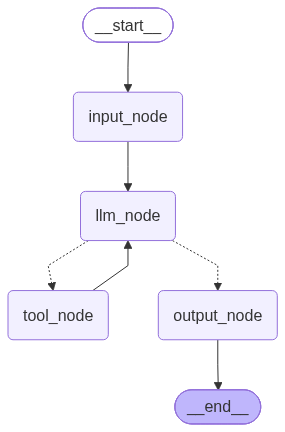

In [15]:
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langgraph.types import Command
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from random import randint
from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str="北京"):
    """
    查询指定城市当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气晴朗，东南风三级，气温 25~30 ℃"

@tool(parse_docstring=True)
def get_news(domain: Literal["AI", "食品安全"]):
    """
    查询特定领域的当日热点

    Args:
        domain: 特定领域
    """
    if domain == "AI":
        return "Anthropic 发布了 Claude Opus-4.8，但通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。"
    else:
        return "双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍"

tools = [get_weather, get_news]

model_with_tools = model.bind_tools(tools=tools)

class OverAllState(MessagesState):
    user_input: str
    final_answer: str

def input_node(state: OverAllState) ->OverAllState:
    return {
        "messages": [HumanMessage(state["user_input"])],
    }

def llm_node(state: OverAllState) -> Command[Literal["tool_node", "output_node"]]:
    messages = state["messages"]
    ai_msg = model_with_tools.invoke(messages)
    if ai_msg.tool_calls:
        goto = "tool_node"
    else:
        goto = "output_node"

    return Command(
        goto=goto,
        update={
            "messages": [ai_msg],
        }
    )

def tool_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = messages[-1]
    tool_calls = ai_msg.tool_calls

    fail_prob = 6 # 失败概率，6表示 60% 概率失败，7 -> 70%，8 -> 80%，依次类推

    for tool_call in tool_calls:
        if tool_call["name"] == "get_weather":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_weather.invoke(tool_call))
        elif tool_call["name"] == "get_news":
            # 生成 [0, 9] 范围内的随机数
            if randint(0, 9) < fail_prob: # 60% 概率因 “网络波动” 而调用失败
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id=tool_call["id"]
                    )
                )
            else:
                messages.append(get_news.invoke(tool_call))
        else:
            messages.append(
                ToolMessage(
                    content="工具名称错误，调用失败，请重试",
                    tool_call_id=tool_call["id"]
                )
            )
    return {
        "messages": messages
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "final_answer": state["messages"][-1].content
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("input_node", input_node)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "input_node")
builder.add_edge("input_node", "llm_node")
builder.add_edge("tool_node", "llm_node")
builder.add_edge("output_node", END)

graph = builder.compile()
ai_res = graph.invoke({
    "user_input": "帮我查询杭州当日天气和AI热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})
food_safety_res = graph.invoke({
    "user_input": "帮我查询当日天气和食品安全相关的热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})

print('=' * 30, '-> ai_res <-', '=' * 30)
print("user_input: ", ai_res["user_input"])
print("final_answer: ", ai_res["final_answer"])
for msg in ai_res["messages"]:
    msg.pretty_print()

print('=' * 30, '-> food_safety_res <-', '=' * 30)
print("user_input: ", food_safety_res["user_input"])
print("final_answer: ", food_safety_res["final_answer"])
for msg in food_safety_res["messages"]:
    msg.pretty_print()

from IPython.display import display
display(graph)

递归限制

主动退出

2026-10-23 20:31:03.003 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 1, remaining_step: 9
2026-10-23 20:31:03.004 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 2, remaining_step: 8
2026-10-23 20:31:03.005 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 3, remaining_step: 7
2026-10-23 20:31:03.005 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 4, remaining_step: 6
2026-10-23 20:31:03.006 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 5, remaining_step: 5
2026-10-23 20:31:03.006 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 6, remaining_step: 4
2026-10-23 20:31:03.007 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 7, remaining_step: 3
2026-10-23 20:31:03.007 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 8, remaining_step: 2
2026-10-23 20:31:03.007 | INFO     | __main__:router:18 - 当前可用超步：2，已不足2步，终止运行图


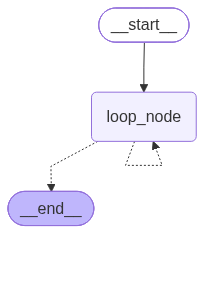

In [16]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.managed import RemainingSteps
from langchain_core.runnables.config import RunnableConfig
from loguru import logger

class OverAllState(TypedDict):
    remaining_steps: RemainingSteps

def loop_node(state: OverAllState, config: RunnableConfig) -> OverAllState:
    cur_step = config["metadata"]["langgraph_step"]
    remaining_steps = state["remaining_steps"]
    logger.info("loop_node, cur_step: {}, remaining_step: {}", cur_step, remaining_steps)

def router(state: OverAllState) -> Literal["loop_node", END]:
    remaining_steps = state["remaining_steps"]
    if remaining_steps < 3:
        logger.info("当前可用超步：{}，已不足2步，终止运行图", remaining_steps)
        return END
    return "loop_node"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("loop_node", loop_node)
builder.add_edge(START, "loop_node")
builder.add_conditional_edges("loop_node", router)

graph = builder.compile()
graph.invoke({}, config={"recursion_limit": 10})

from IPython.display import display
display(graph)

被动抛异常退出

2026-10-23 20:33:34.493 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 1
2026-10-23 20:33:34.494 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 2
2026-10-23 20:33:34.494 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 3
2026-10-23 20:33:34.495 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 4
2026-10-23 20:33:34.495 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 5
2026-10-23 20:33:34.496 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 6
2026-10-23 20:33:34.496 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 7
2026-10-23 20:33:34.496 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 8
2026-10-23 20:33:34.497 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 9
2026-10-23 20:33:34.497 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 10
2026-10-23 20:33:34.497 | INFO     | __main__:<module>:24 - 超步数量达到最大限制，抛出异常: Recursion limit of 10 reached without hitting a stop condition. You can increase t

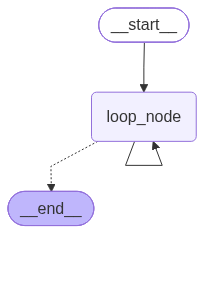

In [17]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.errors import GraphRecursionError
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def loop_node(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("loop_node, cur_step: {}", cur_step)

builder = StateGraph(state_schema=EmptyState)
builder.add_node("loop_node", loop_node)
builder.add_edge(START, "loop_node")
builder.add_edge("loop_node", "loop_node")

graph = builder.compile()
try:
    graph.invoke({}, config={"recursion_limit": 10})
except GraphRecursionError as e:
    logger.info("超步数量达到最大限制，抛出异常: {}", e)

from IPython.display import display
display(graph)

# 重试机制

2026-10-23 20:52:26.853 | INFO     | __main__:node_a:12 - node a 运行
2026-10-23 20:52:27.358 | INFO     | __main__:node_a:12 - node a 运行
2026-10-23 20:52:28.364 | INFO     | __main__:node_a:12 - node a 运行
2026-10-23 20:52:28.365 | INFO     | __main__:<module>:32 - 重试次数耗尽: 网络连接超时...


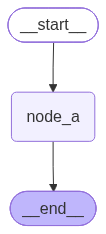

In [18]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import RetryPolicy

from requests.exceptions import HTTPError
from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState) -> EmptyState:
    logger.info(f"node a 运行")
    raise HTTPError("网络连接超时...")

builder = StateGraph(state_schema=EmptyState)
builder.add_node(
    "node_a",
    node_a,
    retry_policy=RetryPolicy(
        max_attempts=3,
        jitter=False
    )
)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()

try:
    graph.invoke({})
except HTTPError as e:
    logger.info("重试次数耗尽: {}", e)

from IPython.display import display
display(graph)

节点缓存

2026-10-23 23:24:23.540 | INFO     | __main__:<module>:31 - 首次调用图
2026-10-23 23:24:23.543 | INFO     | __main__:node_a:14 - node_a 被调用, user: 小明
2026-10-23 23:24:26.548 | INFO     | __main__:node_a:16 - node_a 耗时操作执行完毕
2026-10-23 23:24:26.557 | INFO     | __main__:<module>:32 - 运行结果: {'user': '小明', 'invoke_counts': 1}


2026-10-23 23:24:26.557 | INFO     | __main__:<module>:33 - 相同输入再次调用图
2026-10-23 23:24:26.559 | INFO     | __main__:<module>:34 - 运行结果: {'user': '小明', 'invoke_counts': 1}


2026-10-23 23:24:26.560 | INFO     | __main__:<module>:35 - 不同输入再次调用图
2026-10-23 23:24:26.560 | INFO     | __main__:node_a:14 - node_a 被调用, user: 小花
2026-10-23 23:24:29.566 | INFO     | __main__:node_a:16 - node_a 耗时操作执行完毕
2026-10-23 23:24:29.568 | INFO     | __main__:<module>:36 - 运行结果: {'user': '小花', 'invoke_counts': 1}


2026-10-23 23:24:29.569 | INFO     | __main__:<module>:37 - 不同输入再次调用图
2026-10-23 23:24:29.570 | INFO     | __main__:node_a:14 - node_a 被调用, user: 小花
2026-10-23 23:24:32.574 | INFO

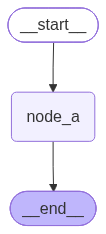

In [19]:
import time
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.cache.memory import InMemoryCache
from langgraph.types import CachePolicy
from operator import add
from loguru import logger

class EmptyState(TypedDict):
    user: str
    invoke_counts: Annotated[int, add]

def node_a(state: EmptyState) -> EmptyState:
    logger.info("node_a 被调用, user: {}", state["user"])
    time.sleep(3) # 模拟耗时操作
    logger.info("node_a 耗时操作执行完毕")
    return {
        "invoke_counts": 1
    }

builder = StateGraph(state_schema=EmptyState)
builder.add_node(
    "node_a",
    node_a,
    cache_policy=CachePolicy(ttl=10)
)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile(cache=InMemoryCache())
logger.info("首次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小明", "invoke_counts": 0}))
logger.info("相同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小明", "invoke_counts": 0}))
logger.info("不同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小花", "invoke_counts": 0}))
logger.info("不同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小花", "invoke_counts": 2}))
time.sleep(10) # 确保第一次调用缓存失效
logger.info("10秒后相同输入再次调用图，此时缓存已失效")
logger.info("运行结果: {}", graph.invoke({"user": "小明", "invoke_counts": 0}))

from IPython.display import display
display(graph)